# Bài thực hành giữa kỳ - Học máy (COMP171202) - Đề 1
**Họ tên:** Nguyễn Đình Bảo &nbsp;&nbsp; **MSSV:** 50.01.104.013

Dữ liệu `diabetes.csv`: 768 bệnh nhân, 8 chỉ số y tế, cột `Outcome` = 1 là có bệnh tiểu đường.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv("diabetes.csv")
print(df.shape)
df.head()

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## Câu 1. Trực quan và làm sạch dữ liệu
### a. Histogram các cột

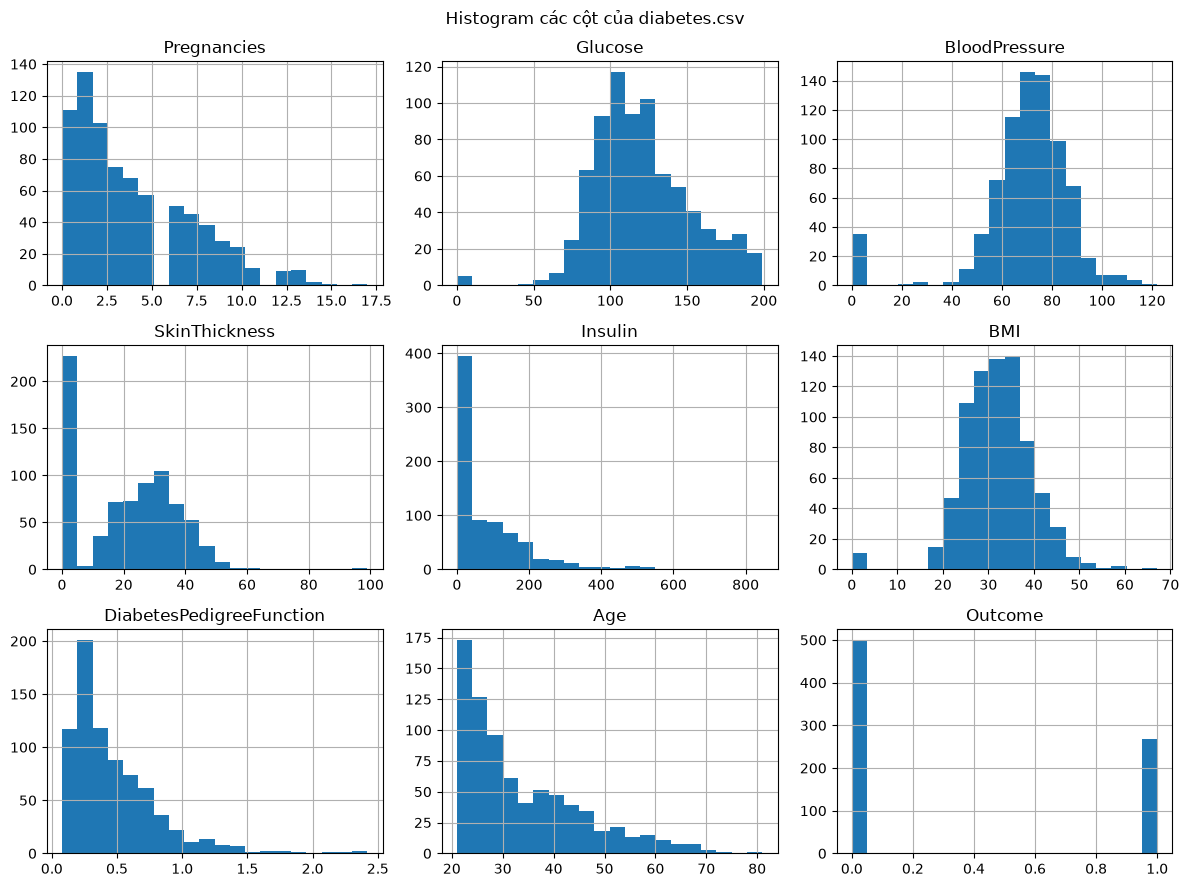

In [2]:
df.hist(bins=20, figsize=(12, 9))
plt.suptitle("Histogram các cột của diabetes.csv")
plt.tight_layout()
plt.show()

### b. Ma trận tương quan của tất cả cột numeric

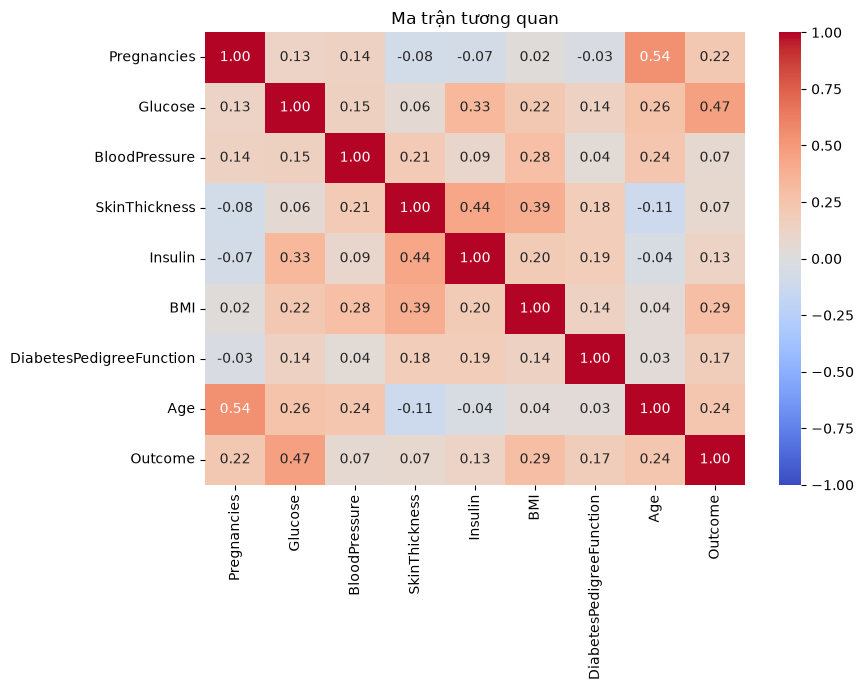

In [3]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.select_dtypes("number").corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Ma trận tương quan")
plt.tight_layout()
plt.show()

### c. Làm sạch dữ liệu
#### (1) Thay ô trống bằng Rolling Mean
Bảng không có ô NaN, nhưng histogram cho thấy Glucose, BloodPressure,
SkinThickness, Insulin, BMI có cột tại 0. Không ai có đường huyết, huyết áp, độ dày nếp da, insulin hay BMI
bằng 0, nên đó là ô trống được ghi thành 0. Đổi các số 0 này thành NaN rồi điền bằng Rolling Mean: trung bình
5 hàng xung quanh ô trống. Nếu cả 5 hàng đều trống thì nới cửa sổ gấp đôi cho tới khi có giá trị.
Pregnancies = 0 là giá trị thật nên giữ nguyên.

In [4]:
print("Số ô NaN ban đầu:", df.isna().sum().sum())

cot_thieu = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
df[cot_thieu] = df[cot_thieu].replace(0, np.nan)
print("\nSố ô trống sau khi đổi 0 thành NaN:")
print(df[cot_thieu].isna().sum())


def rolling_mean(cot, k=5):
    ket_qua = cot
    while ket_qua.isna().any():
        ket_qua = ket_qua.fillna(cot.rolling(k, min_periods=1, center=True).mean())
        k *= 2
    return ket_qua


for c in cot_thieu:
    df[c] = rolling_mean(df[c])
print("\nSố ô trống còn lại:", df.isna().sum().sum())
df.head()

Số ô NaN ban đầu: 0

Số ô trống sau khi đổi 0 thành NaN:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Số ô trống còn lại: 0


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.0,131.0,33.6,0.627,50,1
1,1,85.0,66.0,29.0,94.0,26.6,0.351,31,0
2,8,183.0,64.0,30.5,131.0,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1


#### (2) Chuyển cột Text sang chữ thường
Bảng không có cột kiểu Text, nên tạo cột `BMI_Category` (phân nhóm BMI theo WHO: <18.5, 18.5-25, 25-30, ≥30)
rồi chuyển cột này sang chữ thường.

In [5]:
df["BMI_Category"] = pd.cut(df["BMI"], [0, 18.5, 25, 30, np.inf], right=False,
                            labels=["Underweight", "Normal", "Overweight", "Obese"]).astype(str)
print("Trước:", df["BMI_Category"].unique().tolist())
df["BMI_Category"] = df["BMI_Category"].str.lower()
print("Sau:  ", df["BMI_Category"].unique().tolist())
df[["BMI", "BMI_Category"]].head()

Trước: ['Obese', 'Overweight', 'Normal', 'Underweight']
Sau:   ['obese', 'overweight', 'normal', 'underweight']


,BMI,BMI_Category
0,33.6,obese
1,26.6,overweight
2,23.3,normal
3,28.1,overweight
4,43.1,obese


### d. Mod, Mean, Var, Quartile của cột BloodPressure và xử lý ngoại lệ
Ngoại lệ là giá trị nằm ngoài [Q1 - 1.5·IQR, Q3 + 1.5·IQR] với IQR = Q3 - Q1.
Chọn cách (2): coi ngoại lệ như ô trống rồi điền bằng Rolling Mean.

Mode = 70.00, Mean = 72.34, Var = 147.48
Q1 = 64.00, Q2 (trung vị) = 72.00, Q3 = 80.00

Ngoại lệ nằm ngoài [40.00, 104.00]: 14 hàng
Giá trị ngoại lệ: [24.0, 30.0, 30.0, 38.0, 106.0, 106.0, 106.0, 108.0, 108.0, 110.0, 110.0, 110.0, 114.0, 122.0]
Ngoại lệ còn lại sau khi thay: 0


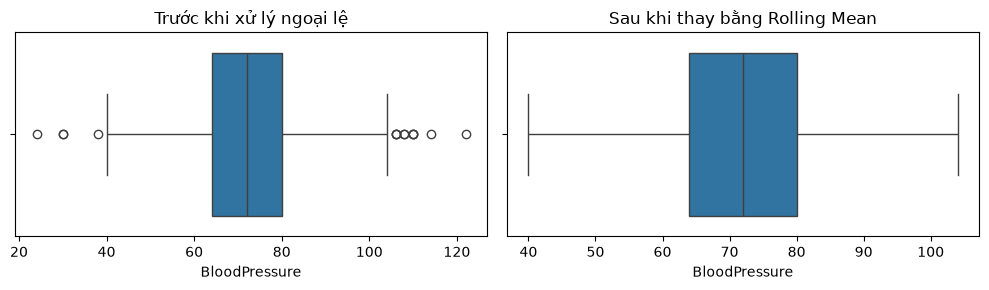

In [6]:
huyet_ap = df["BloodPressure"]
q1, q2, q3 = huyet_ap.quantile([0.25, 0.5, 0.75])
print(f"Mode = {huyet_ap.mode()[0]:.2f}, Mean = {huyet_ap.mean():.2f}, Var = {huyet_ap.var():.2f}")
print(f"Q1 = {q1:.2f}, Q2 (trung vị) = {q2:.2f}, Q3 = {q3:.2f}")

iqr = q3 - q1
duoi, tren = q1 - 1.5 * iqr, q3 + 1.5 * iqr
ngoai_le = ~huyet_ap.between(duoi, tren)
print(f"\nNgoại lệ nằm ngoài [{duoi:.2f}, {tren:.2f}]: {ngoai_le.sum()} hàng")
print("Giá trị ngoại lệ:", huyet_ap[ngoai_le].sort_values().tolist())

df["BloodPressure"] = rolling_mean(huyet_ap.mask(ngoai_le))
print("Ngoại lệ còn lại sau khi thay:", (~df["BloodPressure"].between(duoi, tren)).sum())

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
sns.boxplot(x=huyet_ap, ax=axes[0]).set_title("Trước khi xử lý ngoại lệ")
sns.boxplot(x=df["BloodPressure"], ax=axes[1]).set_title("Sau khi thay bằng Rolling Mean")
plt.tight_layout()
plt.show()

## Câu 2. Phân loại với KNN, Naive Bayes, Decision Tree, AdaBoost
- Đặc trưng: giữ cả 8 chỉ số y tế. Theo ma trận tương quan, cả 8 cột đều tương quan dương với `Outcome`
  (cao nhất Glucose 0.47, BMI 0.29, Age 0.24) và không có cặp đặc trưng nào tương quan quá cao (lớn nhất 0.54
  giữa Age và Pregnancies) nên không cột nào thừa. Bỏ `BMI_Category` vì nó chỉ là BMI chia nhóm.
- Nhãn: `Outcome` (1 = có bệnh).
- Chia train/test 75/25 giữ tỉ lệ lớp (stratify), chuẩn hoá Z-score bằng StandardScaler fit trên tập train.

Train: (576, 8)  Test: (192, 8)


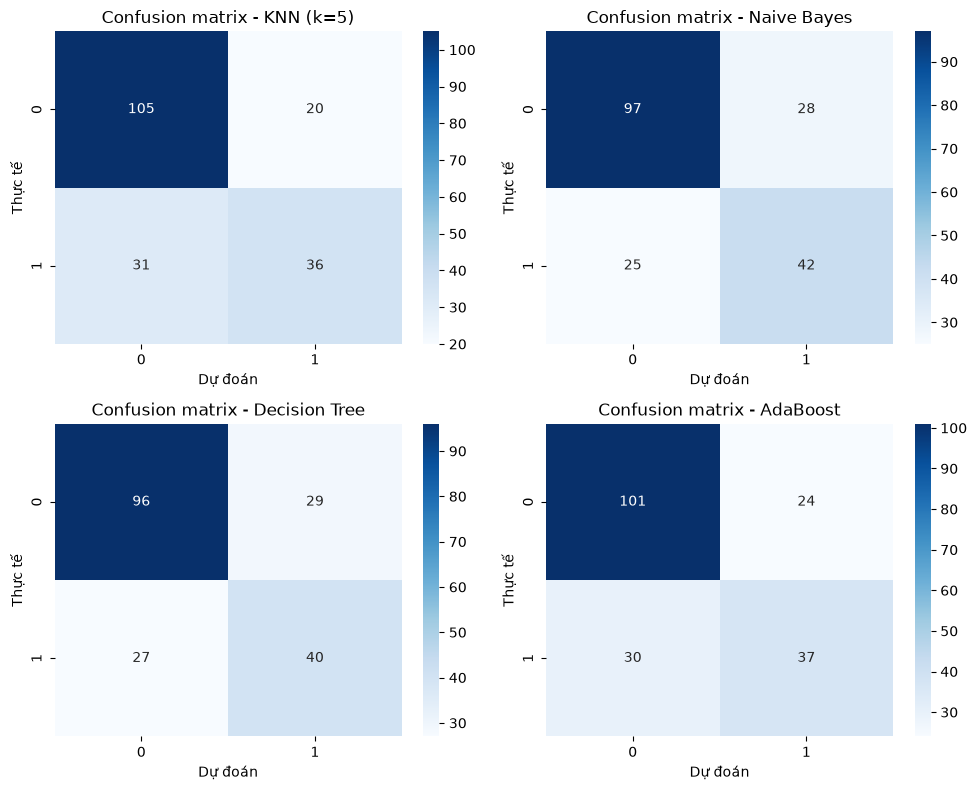

In [7]:
X = df.drop(columns=["Outcome", "BMI_Category"])
y = df["Outcome"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
scaler = StandardScaler().fit(X_train)
X_train, X_test = scaler.transform(X_train), scaler.transform(X_test)
print("Train:", X_train.shape, " Test:", X_test.shape)

cac_model = {
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5, metric="euclidean"),
    "Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(max_depth=10, random_state=42),
    "AdaBoost": AdaBoostClassifier(n_estimators=50, random_state=42),
}

ket_qua = []
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, (ten, model) in zip(axes.flat, cac_model.items()):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    ket_qua.append({
        "Mô hình": ten,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall/Sensitivity": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]),
    })
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues", ax=ax)
    ax.set_title(f"Confusion matrix - {ten}")
    ax.set_xlabel("Dự đoán")
    ax.set_ylabel("Thực tế")
plt.tight_layout()
plt.show()

In [8]:
pd.DataFrame(ket_qua).set_index("Mô hình").round(4)

,Accuracy,Precision,Recall/Sensitivity,F1,AUC
Mô hình,,,,,
KNN (k=5),0.7344,0.6429,0.5373,0.5854,0.7780
Naive Bayes,0.7240,0.6000,0.6269,0.6131,0.7906
Decision Tree,0.7083,0.5797,0.5970,0.5882,0.6836
AdaBoost,0.7188,0.6066,0.5522,0.5781,0.8040


### Nhận xét
- KNN có Accuracy cao nhất (0.734). Naive Bayes có Recall (0.627) và F1 (0.613) cao nhất. AdaBoost có AUC cao nhất (0.804).
- Decision Tree có AUC thấp nhất (0.684). Cây sâu 10 tầng đạt accuracy 0.960 trên tập train nhưng chỉ 0.708 trên tập test: mô hình bị overfitting.
- Đây là bài toán chẩn đoán bệnh nên Recall quan trọng nhất: bỏ sót người bệnh (FN) nguy hiểm hơn báo nhầm người khỏe (FP). Vì vậy chọn Naive Bayes.
- Recall của cả 4 mô hình vẫn thấp (0.537-0.627), tức là còn bỏ sót 37-46% người bệnh trong tập test. Dữ liệu lệch lớp (500 không bệnh, 268 có bệnh) có thể là một nguyên nhân.